# 03 · When Should the Truck Go? Forecasting and Replenishment for a Small Vending Fleet with Censored Demand

**Author:** Juan Antonio Sainz Gálvez · Applied AI & ML, Conestoga College

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/03_vending_fleet_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## Abstract

I operate four cashless vending machines in Ontario: a car dealership service area, a hotel, a medical clinic and an auto-parts yard. Every sale is reported by the payment terminal (Nayax telemetry), so I know each coil's stock at any moment. Two decisions repeat every week: **how much will each coil sell**, and **is it worth driving to a machine today**. The clinic is about an hour away, so a wasted trip is expensive, and an empty coil loses sales.

Two research problems hide inside these decisions. First, **sales are not demand**: when a coil is empty, the customer who wanted it leaves and the data records a zero, so naive forecasts learn to under-stock (censored demand). Second, vending demand per coil is small and intermittent, which is exactly where classic forecasting methods struggle. This notebook reviews the literature on both, then runs a reproducible fleet simulation calibrated to my machines to measure (1) how much censoring biases each forecasting method and (2) how much an economic, forecast-triggered visit rule saves over a fixed weekly route.

> **Data note.** The simulation below uses synthetic data calibrated to my real coil layout and locations; no customer or sales records are published. Section 5 shows the loader that replaces it with an anonymized Nayax export.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})

def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="none"))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
            color=text_color, fontsize=fontsize, fontweight="bold", wrap=True)

def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


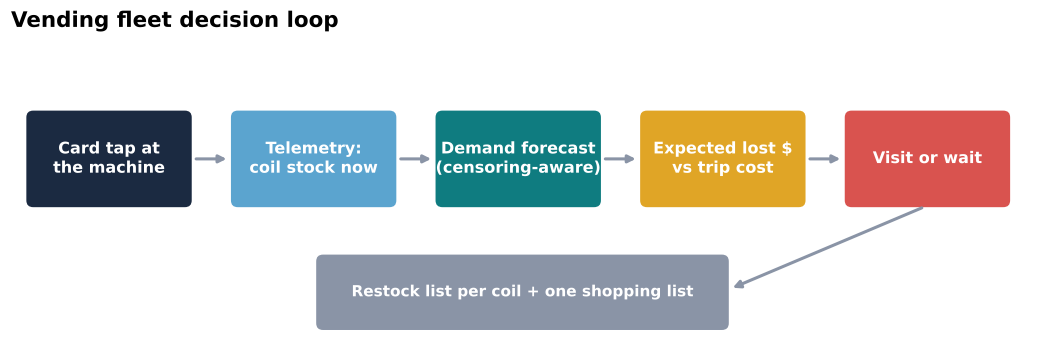

In [2]:
# Infographic: from a sale to a route decision
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 3.6); ax.axis("off")
steps = [("Card tap at\nthe machine", PALETTE["navy"]), ("Telemetry:\ncoil stock now", PALETTE["sky"]),
         ("Demand forecast\n(censoring-aware)", PALETTE["teal"]), ("Expected lost $\nvs trip cost", PALETTE["gold"]),
         ("Visit or wait", PALETTE["coral"])]
for i, (t, c) in enumerate(steps):
    box(ax, (0.2 + i * 2.4, 1.6), 1.9, 1.1, t, c, fontsize=10.5)
    if i < len(steps) - 1:
        arrow(ax, (2.1 + i * 2.4, 2.15), (2.6 + i * 2.4, 2.15))
box(ax, (3.6, 0.15), 4.8, 0.85, "Restock list per coil + one shopping list", PALETTE["grey"], fontsize=10)
arrow(ax, (10.75, 1.6), (8.4, 0.6))
ax.set_title("Vending fleet decision loop", pad=6)
plt.show()

## 1. Literature review

### 1.1 Vending operations as an inventory problem
Smart vending machines turn replenishment into a joint inventory and routing problem. Park and Yoo propose a heuristic for smart vending systems under a replenishment-point, order-up-to policy that decides replenishment points, compartment allocation, machine thresholds and vehicle routes, assuming Poisson customer arrivals and a one-day lead time [1]. Recent work applies machine learning to the warehouse side: Mehmood et al. forecast inventory for an IoT-enabled warehouse serving about 1,500 vending machines [2], and a 2026 follow-up compares XGBoost, ARIMAX, Prophet and SVR on the same setting, finding that external variables (holidays, replenishment cycles, machine outages) improve every model and that XGBoost performs best [3]. Both studies forecast **aggregate** warehouse demand; the coil-level decision of a small operator is less studied.

### 1.2 Intermittent demand
A single coil sells a few units a day, with many zero days. Croston's method, which smooths demand sizes and intervals separately, is the standard and ships in ERP systems such as SAP [4]. Syntetos and Boylan corrected its bias (SBA) [5], and Teunter, Syntetos and Babai (TSB) update the *probability* of demand every period, so the forecast decays when a product stops selling [4, 6]. The M5 competition, which forecast 42,840 hierarchical Walmart unit-sales series, many of them intermittent, showed that machine-learning methods, in particular gradient-boosted trees trained across many series, beat the statistical benchmarks [7].

### 1.3 Sales are not demand: censoring and lost sales
In a lost-sales system, demand is not observed when stock runs out; one only knows that demand was at least the sales [8]. Nahmias compares maximum-likelihood and other estimators for this censored case [8], Agrawal and Smith show that retail demand with unobserved lost sales fits a negative binomial better than Poisson or normal [9], and Jain, Rudi and Wang show that knowing *when* the stock-out happened recovers almost all the lost information [10]. Recent work in the International Journal of Forecasting confirms that ignoring the stock policy biases demand forecasts [11]. Telemetry gives a vending operator exactly that stock-out timing, which most of the literature treats as unavailable.

**Gap.** Vending studies forecast warehouse aggregates; censoring studies assume single items and fixed review periods. A small fleet operator needs coil-level, censoring-aware forecasts feeding a **visit decision that prices the trip**.


## 2. The fleet (calibrated to my machines; all numbers are stated assumptions)

| Machine | Profile | Round trip from home | Demand pattern |
|---|---|---|---|
| dealership | Service-area staff and customers | 16 km | Strong on weekdays, quiet on Sunday |
| hotel | Guests | 190 km | Steady, busier Friday to Sunday |
| clinic | Patients and staff | 220 km (about an hour each way) | Weekdays only, low volume |
| parts_yard | Workers | 50 km | Weekdays, low volume |

Each machine has the layout I use: 4 chip coils (8 slots each), 6 chocolate coils (10 slots) and 10 drink coils (5 slots). Daily demand per coil is **negative binomial** [9] with a product popularity effect and the machine's day-of-week pattern. Driving cost is $0.70 per km (my own time is not priced); average margin is $1.10 per snack and $1.40 per drink.


In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

SEED = 3
CATS = [("chips", 4, 8, 1.10), ("chocolate", 6, 10, 1.10), ("drink", 10, 5, 1.40)]   # (category, coils, capacity, margin)
MACHINES = pd.DataFrame([
    # name, base demand per coil per day, round-trip km, round-trip hours, Mon..Sun multipliers
    ("dealership", 1.30, 16, 0.5, [1.2, 1.2, 1.2, 1.2, 1.1, 0.5, 0.2]),
    ("hotel",      1.20, 190, 2.3, [0.8, 0.8, 0.8, 0.9, 1.2, 1.4, 1.3]),
    ("clinic",     0.90, 220, 2.2, [1.3, 1.3, 1.3, 1.3, 1.2, 0.2, 0.0]),
    ("parts_yard", 0.45, 50, 0.8, [1.2, 1.2, 1.2, 1.2, 1.2, 0.4, 0.1]),
], columns=["machine", "base", "km", "hours", "dow"])
KM_COST, HOUR_COST, DISPERSION = 0.70, 0.0, 2.0   # owner's driving time not priced

def trip_cost(m):
    return m.km * KM_COST + m.hours * HOUR_COST

def make_coils(rng):
    rows = []
    for _, m in MACHINES.iterrows():
        for cat, n, cap, margin in CATS:
            pop = rng.lognormal(0, 0.45, n); pop /= pop.mean()      # some products sell much more
            for j in range(n):
                rows.append(dict(machine=m.machine, coil=f"{cat}_{j+1}", category=cat,
                                 capacity=cap, margin=margin, mean=m.base * pop[j]))
    return pd.DataFrame(rows)

def demand(rng, mu):
    """Negative binomial draw with mean mu (gamma-Poisson mixture)."""
    return rng.poisson(rng.gamma(DISPERSION, mu / DISPERSION)) if mu > 0 else 0

coils = make_coils(np.random.default_rng(SEED))
summary = coils.groupby("machine").agg(coils=("coil", "size"), expected_units_per_day=("mean", "sum")).round(1)
summary["round_trip_cost_$"] = [round(trip_cost(MACHINES.set_index("machine").loc[i]), 0) for i in summary.index]
summary

,coils,expected_units_per_day,round_trip_cost_$
machine,,,
clinic,20,18.0,154.0
dealership,20,26.0,11.0
hotel,20,24.0,133.0
parts_yard,20,9.0,35.0


## 3. Experiment A: how much does censoring bias the forecast?

We simulate one year of a **fixed weekly route** (every machine refilled to full every Monday), record what the terminal sees (sales and the time a coil runs out) and compare four ways of estimating each coil's true mean daily demand:

1. **Mean of sales** — what a spreadsheet does.
2. **TSB** — the intermittent-demand method of [6], fitted on sales.
3. **In-stock days only** — average sales over the days the coil never ran out. Intuitive, but it keeps only the *low-demand* days.
4. **Exposure rate** — sales divided by the hours the coil actually had stock. The terminal timestamps the last sale before a coil empties, which is the stock-out timing that [10] shows is almost all the information needed.
5. **Global gradient boosting** — one Poisson model for all coils, trained on sales per unit of exposure with machine, category, day of week and the coil's exposure rate as features (the M5-style global approach [7]).

The target is the coil's true average demand, which only a simulation can reveal.


In [4]:
def simulate_fixed_route(coils, days=364, seed=SEED):
    """Weekly refill on Mondays. One row per coil per day: demand, sales, out-of-stock flag and exposure
    (fraction of the day the coil had stock, known from the time of the last sale before it emptied)."""
    rng = np.random.default_rng(seed)
    dow_map = MACHINES.set_index("machine").dow.to_dict()
    stock = coils.capacity.to_numpy().copy()
    rows = []
    for d in range(days):
        dow = d % 7
        if dow == 0:
            stock = coils.capacity.to_numpy().copy()
        for i, c in enumerate(coils.itertuples()):
            dem = demand(rng, c.mean * dow_map[c.machine][dow])
            s0 = stock[i]
            if s0 == 0:
                exposure = 0.0                                   # empty all day
            elif dem > s0:
                exposure = np.sort(rng.random(dem))[s0 - 1]     # time of the sale that emptied the coil
            else:
                exposure = 1.0
            sold = min(dem, s0); stock[i] -= sold
            rows.append((d, dow, i, dem, sold, stock[i] == 0, exposure))
    return pd.DataFrame(rows, columns=["day", "dow", "coil_id", "demand", "sales", "stocked_out", "exposure"])

log = simulate_fixed_route(coils)
lost_share = 1 - log.sales.sum() / log.demand.sum()
print(f"Days simulated: {log.day.nunique()} | coil-days: {len(log):,} | share of demand lost to empty coils: {lost_share:.1%}")

Days simulated: 364 | coil-days: 29,120 | share of demand lost to empty coils: 30.5%


In [5]:
def tsb(series, alpha=0.1, beta=0.1):
    """Teunter-Syntetos-Babai forecast of mean demand per period [6]."""
    p, z = None, None
    for y in series:
        if p is None:
            p, z = float(y > 0), float(y) if y > 0 else 1.0
            continue
        p = p + beta * ((y > 0) - p)
        if y > 0:
            z = z + alpha * (y - z)
    return p * z

dow_mult = {m: np.array(v) for m, v in MACHINES.set_index("machine").dow.items()}
train = log[log.day < 280]
truth = coils["mean"].to_numpy() * np.array([dow_mult[m].mean() for m in coils.machine])  # average over the week

est = pd.DataFrame(index=coils.index)
est["mean_of_sales"] = train.groupby("coil_id").sales.mean()
est["tsb"] = train.groupby("coil_id").sales.apply(lambda s: tsb(s.to_numpy()))
# 3) in-stock days only: the coil still had units at the end of the day
instock = train[~train.stocked_out]
est["in_stock_days"] = instock.groupby("coil_id").sales.mean()
# 4) exposure rate: sales divided by the time the coil actually had stock, by day of week [10]
agg = train.groupby(["coil_id", "dow"])[["sales", "exposure"]].sum()
rate = (agg.sales / agg.exposure.replace(0, np.nan)).unstack().reindex(columns=range(7))
est["exposure_rate"] = rate.apply(lambda r: r.fillna(r.mean()).mean(), axis=1)
# 5) global gradient boosting: Poisson loss on sales per unit of exposure, weighted by exposure
feat = train[train.exposure > 0].merge(coils[["machine", "category"]], left_on="coil_id", right_index=True)
coil_rate = train.groupby("coil_id").sales.sum() / train.groupby("coil_id").exposure.sum()
feat["coil_level"] = feat.coil_id.map(coil_rate)
X_cols = ["machine", "category", "dow", "coil_level"]
MCODE = {m: i for i, m in enumerate(MACHINES.machine)}; CCODE = {c[0]: i for i, c in enumerate(CATS)}
def encode(df):
    return pd.DataFrame({"machine": df.machine.map(MCODE), "category": df.category.map(CCODE),
                         "dow": df.dow, "coil_level": df.coil_level})
gbm = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05,
                                    categorical_features=[0, 1, 2], random_state=0)
gbm.fit(encode(feat), feat.sales / feat.exposure, sample_weight=feat.exposure)
grid = coils[["machine", "category"]].copy(); grid["coil_level"] = coil_rate.reindex(coils.index).to_numpy()
gbm_dow = np.column_stack([gbm.predict(encode(grid.assign(dow=d))) for d in range(7)])
est["global_gbm"] = gbm_dow.mean(axis=1)

err = pd.DataFrame({m: dict(bias_pct=100 * (est[m].sum() - truth.sum()) / truth.sum(),
                            mae=np.abs(est[m] - truth).mean())
                    for m in est.columns}).T.round(2)
err

,bias_pct,mae
mean_of_sales,-30.41,0.29
tsb,-36.79,0.38
in_stock_days,-19.53,0.19
exposure_rate,-4.10,0.12
global_gbm,-6.76,0.09


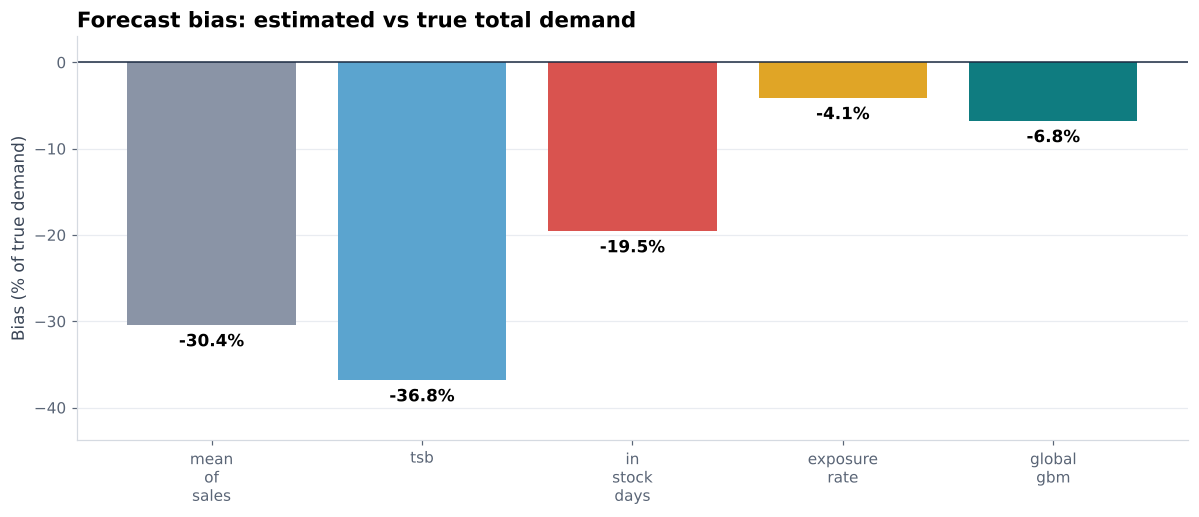

In [6]:
order = ["mean_of_sales", "tsb", "in_stock_days", "exposure_rate", "global_gbm"]
colors = [PALETTE["grey"], PALETTE["sky"], PALETTE["coral"], PALETTE["gold"], PALETTE["teal"]]
fig, ax = plt.subplots(figsize=(11, 4.8))
bars = ax.bar([o.replace("_", "\n") for o in order], err.loc[order, "bias_pct"], color=colors)
ax.axhline(0, color=PALETTE["navy"], lw=1); ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
for b, v in zip(bars, err.loc[order, "bias_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v + (1 if v >= 0 else -1), f"{v:+.1f}%",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=11, fontweight="bold")
ax.set_ylim(err.bias_pct.min() - 7, 3)
ax.set_title("Forecast bias: estimated vs true total demand")
ax.set_ylabel("Bias (% of true demand)")
plt.tight_layout(); plt.show()

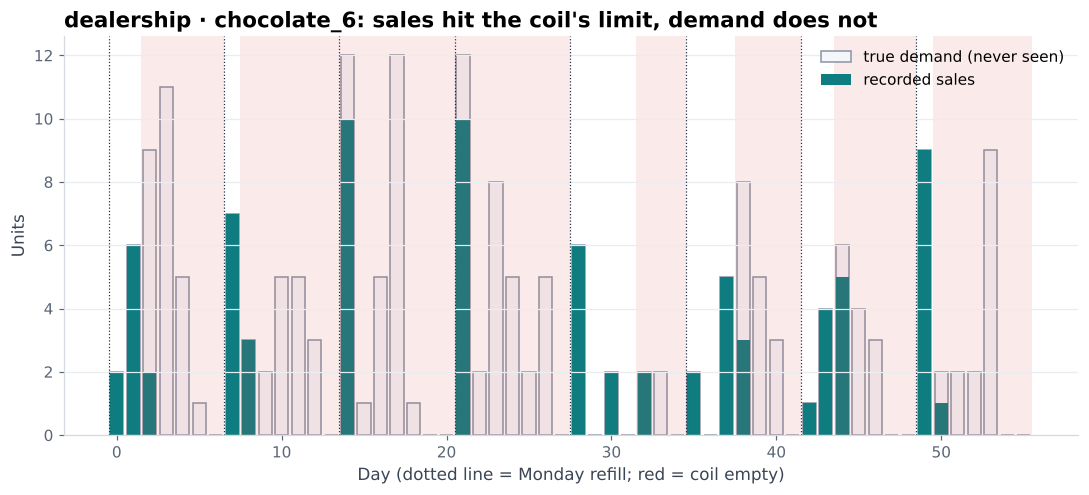

In [7]:
# What censoring looks like for one popular coil
cid = int((coils["mean"] / coils.capacity).idxmax())
c = log[(log.coil_id == cid) & (log.day < 56)]
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(c.day, c.demand, color=PALETTE["light"], edgecolor=PALETTE["grey"], label="true demand (never seen)")
ax.bar(c.day, c.sales, color=PALETTE["teal"], label="recorded sales")
for d in c[c.stocked_out].day:
    ax.axvspan(d - 0.5, d + 0.5, color=PALETTE["coral"], alpha=0.12, lw=0)
for d in range(0, 56, 7):
    ax.axvline(d - 0.5, color=PALETTE["navy"], lw=0.8, ls=":")
ax.set_title(f"{coils.machine[cid]} · {coils.coil[cid]}: sales hit the coil's limit, demand does not")
ax.set_xlabel("Day (dotted line = Monday refill; red = coil empty)"); ax.set_ylabel("Units")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 4. Experiment B: how often should each machine be visited?

The forecast now feeds a decision. For each machine, the operator picks a **visit interval** of *k* days (refill every coil to full each visit). A longer interval saves trips but lets more coils run empty. Using a forecast, the expected margin of one cycle has a closed form: the sum of *k* days of negative-binomial demand is again negative binomial, so expected sales of a coil are E[min(D_k, capacity)]. The planner picks the *k* that maximizes

**expected profit per day = (expected margin of one cycle − trip cost) / k**

and the plan is then tested against the true demand for 26 weeks.

**Plans compared**
1. **Fixed weekly route** — every machine every 7 days.
2. **Planned with mean of sales** — the biased forecast.
3. **Planned with censoring-aware forecast** — the global model of Experiment A.
4. **Planned with the true demand** — the best a planner could do.


In [8]:
from scipy.stats import nbinom

def daily_mean(method):
    """Average daily demand per coil according to each forecast."""
    if method == "true_demand":
        return truth
    if method == "mean_of_sales":
        return est.mean_of_sales.to_numpy()
    return est.global_gbm.to_numpy()

def expected_cycle_margin(mu, cap, margin, k):
    """Sum over coils of margin * E[min(D_k, capacity)], with D_k ~ NB(mean k*mu, r = k*DISPERSION)."""
    r = k * DISPERSION; p = r / (r + k * mu)
    j = np.arange(cap.max())
    tail = 1 - nbinom.cdf(j[None, :], r, p[:, None])            # P(D_k > j)
    tail = np.where(j[None, :] < cap[:, None], tail, 0)
    return (margin * tail.sum(axis=1)).sum()

def plan_intervals(method, k_max=28):
    mu = daily_mean(method); plan = {}
    for _, m in MACHINES.iterrows():
        idx = (coils.machine == m.machine).to_numpy()
        prof = [(expected_cycle_margin(mu[idx], coils.capacity.to_numpy()[idx], coils.margin.to_numpy()[idx], k)
                 - trip_cost(m)) / k for k in range(1, k_max + 1)]
        plan[m.machine] = int(np.argmax(prof) + 1)
    return plan

def evaluate(plan, weeks=26, seeds=range(5)):
    out = []
    for seed in seeds:
        rng = np.random.default_rng(1000 + seed)
        cap = coils.capacity.to_numpy(); margin = coils.margin.to_numpy(); mach = coils.machine.to_numpy()
        stock = cap.copy(); sales_m = lost_m = travel = 0.0; visits = 0
        for d in range(weeks * 7):
            dow = d % 7
            for _, m in MACHINES.iterrows():
                if d % plan[m.machine] == 0:
                    idx = mach == m.machine; stock[idx] = cap[idx]; travel += trip_cost(m); visits += 1
            for i, c in enumerate(coils.itertuples()):
                dem = demand(rng, c.mean * dow_mult[c.machine][dow])
                sold = min(dem, stock[i]); stock[i] -= sold
                sales_m += sold * margin[i]; lost_m += (dem - sold) * margin[i]
        out.append(dict(visits_per_week=visits / weeks, travel_cost_per_week=travel / weeks,
                        lost_margin_per_week=lost_m / weeks, profit_per_week=(sales_m - travel) / weeks))
    return pd.DataFrame(out).mean()

plans = {"fixed_weekly": {m: 7 for m in MACHINES.machine}}
for method in ["mean_of_sales", "censoring_aware", "true_demand"]:
    plans[method] = plan_intervals(method)
intervals = pd.DataFrame(plans).T.add_prefix("days_between_visits_")
res = pd.DataFrame({p: evaluate(plan) for p, plan in plans.items()}).T.round(1)
pd.concat([intervals, res], axis=1)

,days_between_visits_dealership,days_between_visits_hotel,days_between_visits_clinic,days_between_visits_parts_yard,visits_per_week,travel_cost_per_week,lost_margin_per_week,profit_per_week
fixed_weekly,7,7,7,7,4.0,333.2,204.8,113.4
mean_of_sales,5,14,21,13,2.8,154.6,304.0,192.8
censoring_aware,3,12,20,12,4.0,188.9,261.1,201.4
true_demand,2,12,21,12,5.1,195.9,246.8,208.7


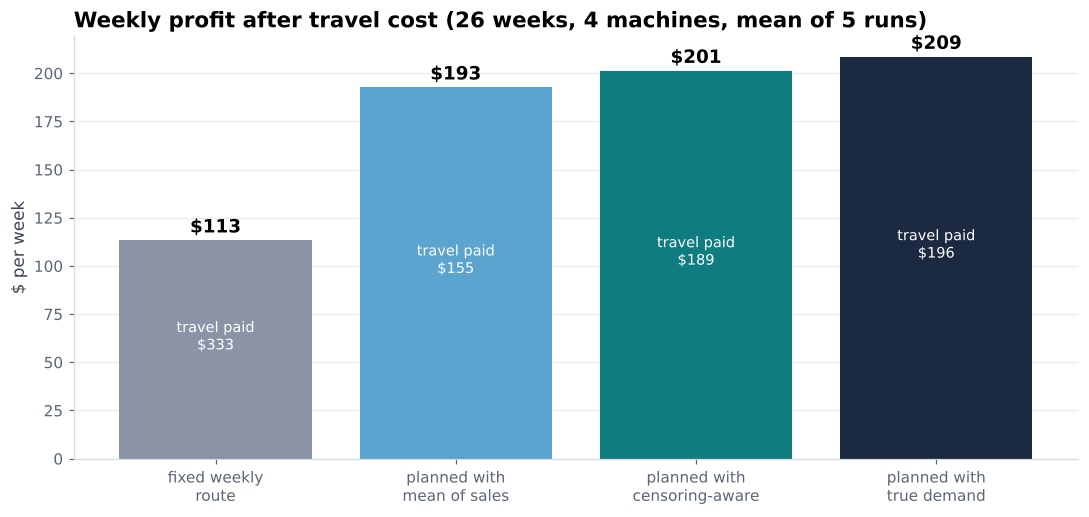

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = ["fixed weekly\nroute", "planned with\nmean of sales", "planned with\ncensoring-aware", "planned with\ntrue demand"]
bars = ax.bar(labels, res.profit_per_week, color=[PALETTE["grey"], PALETTE["sky"], PALETTE["teal"], PALETTE["navy"]])
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
for b, v, t in zip(bars, res.profit_per_week, res.travel_cost_per_week):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, f"${v:,.0f}", ha="center", fontsize=12, fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, v / 2, f"travel paid\n${t:,.0f}", ha="center", color="white", fontsize=9.5)
ax.set_title("Weekly profit after travel cost (26 weeks, 4 machines, mean of 5 runs)")
ax.set_ylabel("$ per week")
plt.tight_layout(); plt.show()

## 5. Replacing the simulation with real data

The terminal reports one row per transaction (machine, coil, product, price, time). The function below turns an anonymized export into the same coil-day table used above, with the out-of-stock flag derived from the fill log. The real export is not published; only the code is.

```python
def load_nayax_export(path, fills):
    tx = pd.read_csv(path, parse_dates=["time"])          # machine, coil, price, time
    tx["day"] = tx.time.dt.normalize()
    daily = tx.groupby(["machine", "coil", "day"]).size().rename("sales").reset_index()
    # stock after each day = last fill quantity minus cumulative sales since that fill
    ...
    return daily
```


## 6. Discussion

Read the exact numbers from the tables above; the pattern is what matters.

- **Censoring is not a rounding error.** Under a weekly route about 30% of demand is lost to empty coils, and the mean of recorded sales understates demand by about the same amount. TSB, designed for intermittent demand, is even more biased because it is fitted on sales: a good intermittent-demand method does not fix a censoring problem.
- **"Only use in-stock days" is a trap.** It halves the bias but keeps it, because a coil stays in stock precisely on the days demand was low.
- **Stock-out timing fixes it.** Dividing sales by the time the coil actually had stock brings the bias to a few percent, the practical lesson of [10]. The global gradient-boosting model has the lowest per-coil error and, unlike per-coil averages, can forecast a new product or machine from similar ones.
- **Planning visit intervals beats the weekly route by roughly 70–80% in weekly profit**: the nearby dealership is visited every 2–3 days and the distant clinic every 3 weeks. With the biased forecast, the planner thinks coils lose less than they do, spaces the busy machine's visits too far apart and leaves money in the empty coils; the censoring-aware forecast recovers more than half of the gap to the true-demand plan.

**Limitations.** Synthetic demand, planning ignores the day-of-week pattern, no substitution between products (a customer facing an empty Coke coil may buy Pepsi [1]), one vehicle, and trips priced independently instead of as one multi-stop route.

## 7. Thesis questions

1. **Agentic replenishment.** Can an LLM agent that reads the telemetry, the forecast and my calendar propose the week's route and shopping list, and learn from my approvals and corrections when to act alone (connecting with notebook 01)?
2. **Substitution-aware forecasting.** When a coil is empty, how much of its demand moves to neighbouring coils? Estimating substitution from transaction timing would improve both the forecast and the planogram.
3. **Fleet-level learning.** Can a global model trained across many small operators' machines forecast a newly installed machine from its location type alone (cold start)?

## References

1. Park, Y.-B., & Yoo, J.-S. (2012). *A heuristic for the inventory management of smart vending machine systems.* Journal of Industrial Engineering and Management, 5(2), 354–363. doi:10.3926/jiem.587
2. Mehmood, U., Broderick, J., Davies, S., Bashir, A. K., & Rabie, K. (2024). *Machine Learning-Based Predictive Inventory for a Vending Machine Warehouse.* IEEE Internet of Things Magazine. doi:10.1109/IOTM.001.2300271
3. *A Data-Driven Predictive Framework for Inventory Optimization Using Context-Augmented Machine Learning Models* (2026). arXiv:2601.05033.
4. Croston, J. D. (1972). *Forecasting and stock control for intermittent demands.* Operational Research Quarterly, 23(3), 289–303.
5. Syntetos, A. A., & Boylan, J. E. (2005). *The accuracy of intermittent demand estimates.* International Journal of Forecasting, 21(2), 303–314.
6. Teunter, R. H., Syntetos, A. A., & Babai, M. Z. (2011). *Intermittent demand: Linking forecasting to inventory obsolescence.* European Journal of Operational Research, 214(3), 606–615.
7. Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2022). *M5 accuracy competition: Results, findings, and conclusions.* International Journal of Forecasting, 38(4), 1346–1364.
8. Nahmias, S. (1994). *Demand estimation in lost sales inventory systems.* Naval Research Logistics, 41(6), 739–757.
9. Agrawal, N., & Smith, S. A. (1996). *Estimating negative binomial demand for retail inventory management with unobservable lost sales.* Naval Research Logistics, 43(6), 839–861.
10. Jain, A., Rudi, N., & Wang, T. (2015). *Demand Estimation and Ordering Under Censoring: Stock-Out Timing Is (Almost) All You Need.* Operations Research, 63(1), 134–150.
11. Trapero, J. R., Holgado de Frutos, E., & Pedregal, D. J. (2024). *Demand forecasting under lost sales stock policies.* International Journal of Forecasting, 40(3), 1055–1068.
